<a href="https://colab.research.google.com/github/hariharan-vs/facial-expression-detection/blob/main/facial_expression_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [3]:
!pip -q install kagglehub gradio scikit-learn seaborn

In [4]:
import kagglehub
import os

dataset_path = kagglehub.dataset_download("msambare/fer2013")
print("Dataset downloaded to:", dataset_path)
print("Contents:", os.listdir(dataset_path))

Using Colab cache for faster access to the 'fer2013' dataset.
Dataset downloaded to: /kaggle/input/fer2013
Contents: ['test', 'train']


In [5]:
import os
from pathlib import Path

base = Path(dataset_path)

train_dirs = [
    p for p in base.rglob("train")
    if p.is_dir() and any(x.is_dir() for x in p.iterdir())
]
test_dirs = [
    p for p in base.rglob("test")
    if p.is_dir() and any(x.is_dir() for x in p.iterdir())
]

print("Train folders:", train_dirs[:3])
print("Test folders:", test_dirs[:3])

assert train_dirs and test_dirs, (
    "Could not find train/test image folders. "
    "Inspect dataset_path and update the paths."
)

train_dir = train_dirs[0]
test_dir = test_dirs[0]

print("Train classes:", sorted(
    p.name for p in train_dir.iterdir() if p.is_dir()
))

Train folders: [PosixPath('/kaggle/input/fer2013/train')]
Test folders: [PosixPath('/kaggle/input/fer2013/test')]
Train classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


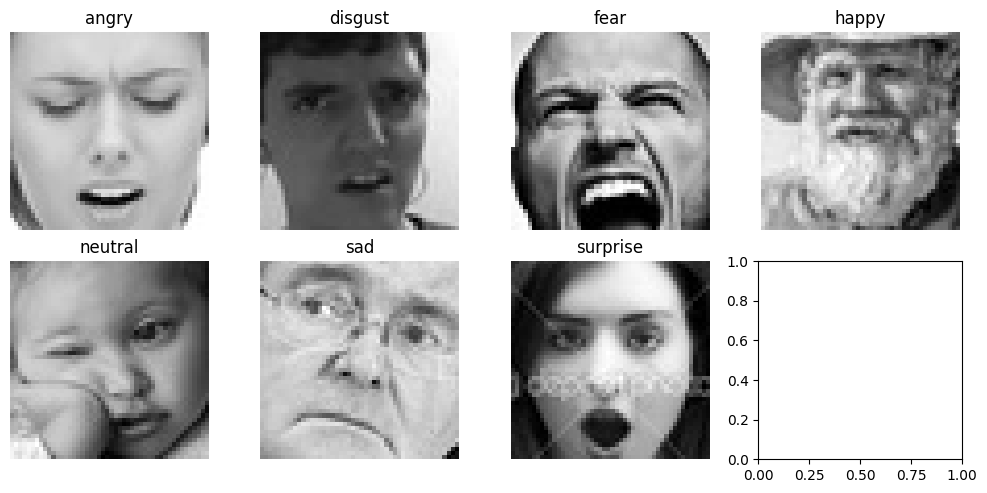

In [6]:
import matplotlib.pyplot as plt
from PIL import Image

classes = sorted(p.name for p in train_dir.iterdir() if p.is_dir())

fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for ax, cls in zip(axes.flat, classes):
    image_path = next((train_dir / cls).glob("*"))
    img = Image.open(image_path).convert("L")
    ax.imshow(img, cmap="gray")
    ax.set_title(cls)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training on:", device)

train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((48, 48)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])

eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((48, 48)),
    transforms.ToTensor(),
])

train_full = datasets.ImageFolder(train_dir, transform=train_transform)
eval_full = datasets.ImageFolder(test_dir, transform=eval_transform)

class_names = train_full.classes
assert class_names == eval_full.classes, "Class order differs!"

# Limit data to keep the experiment manageable.
def balanced_indices(dataset, max_per_class, seed=42):
    rng = random.Random(seed)
    labels = np.array(dataset.targets)
    chosen = []

    for c in range(len(dataset.classes)):
        indices = np.where(labels == c)[0].tolist()
        rng.shuffle(indices)
        chosen.extend(indices[:max_per_class])

    rng.shuffle(chosen)
    return chosen

train_indices = balanced_indices(train_full, 600)
test_indices = balanced_indices(eval_full, 150)

train_subset = Subset(train_full, train_indices)
val_size = max(1, int(0.15 * len(train_subset)))
train_size = len(train_subset) - val_size

train_data, val_data = random_split(
    train_subset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)
test_data = Subset(eval_full, test_indices)

train_loader = DataLoader(
    train_data, batch_size=64, shuffle=True, num_workers=2
)
val_loader = DataLoader(
    val_data, batch_size=128, shuffle=False, num_workers=2
)
test_loader = DataLoader(
    test_data, batch_size=128, shuffle=False, num_workers=2
)

print("Classes:", class_names)
print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Testing:", len(test_data))

Training on: cuda
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Training: 3431
Validation: 605
Testing: 1011


In [8]:
class EmotionCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128 * 6 * 6, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = EmotionCNN(num_classes=len(class_names)).to(device)

print(model)
print("Parameters:", sum(p.numel() for p in model.parameters()))

EmotionCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=4608, out_features=128, bi

In [9]:
import time
import copy
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 5
history = {
    "train_loss": [], "train_acc": [],
    "val_loss": [], "val_acc": []
}

best_val_acc = 0.0
best_state = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):
    start = time.time()

    # Training phase
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_loss = total_loss / total
    train_acc = correct / total

    # Validation phase: no weight updates
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state = copy.deepcopy(model.state_dict())

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train acc: {train_acc:.1%} | "
        f"Val acc: {val_acc:.1%} | "
        f"Time: {time.time()-start:.1f}s"
    )

model.load_state_dict(best_state)
torch.save(model.state_dict(), "emotion_cnn.pth")
print("Best validation accuracy:", f"{best_val_acc:.1%}")
print("Saved model to emotion_cnn.pth")

Epoch 1/5 | Train loss: 2.0668 | Train acc: 18.4% | Val acc: 19.7% | Time: 8.9s
Epoch 2/5 | Train loss: 1.8935 | Train acc: 21.9% | Val acc: 22.6% | Time: 2.6s
Epoch 3/5 | Train loss: 1.8194 | Train acc: 25.8% | Val acc: 26.0% | Time: 2.5s
Epoch 4/5 | Train loss: 1.7356 | Train acc: 30.0% | Val acc: 30.9% | Time: 2.5s
Epoch 5/5 | Train loss: 1.6433 | Train acc: 35.0% | Val acc: 30.9% | Time: 2.6s
Best validation accuracy: 30.9%
Saved model to emotion_cnn.pth


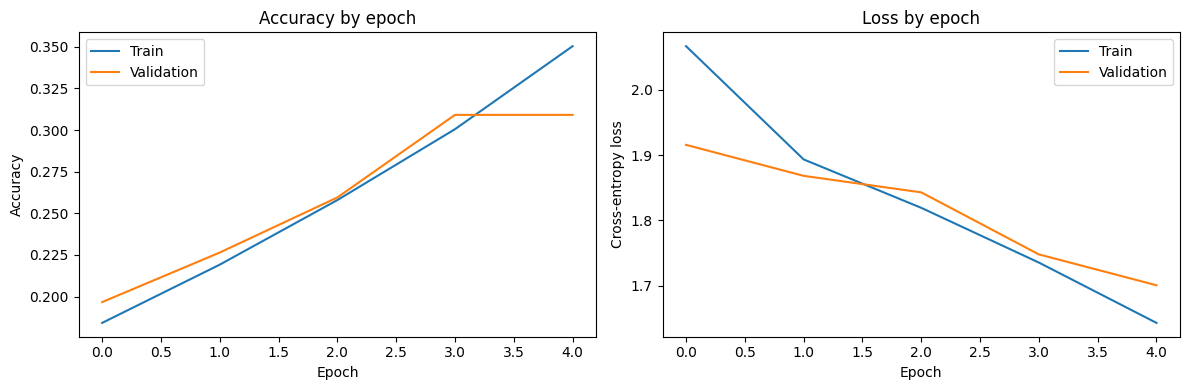

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["train_acc"], label="Train")
axes[0].plot(history["val_acc"], label="Validation")
axes[0].set_title("Accuracy by epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history["train_loss"], label="Train")
axes[1].plot(history["val_loss"], label="Validation")
axes[1].set_title("Loss by epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-entropy loss")
axes[1].legend()

plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

       angry       0.16      0.25      0.19       150
     disgust       0.31      0.34      0.32       111
        fear       0.16      0.03      0.05       150
       happy       0.43      0.39      0.41       150
     neutral       0.00      0.00      0.00       150
         sad       0.21      0.39      0.27       150
    surprise       0.43      0.59      0.49       150

    accuracy                           0.28      1011
   macro avg       0.24      0.28      0.25      1011
weighted avg       0.24      0.28      0.25      1011



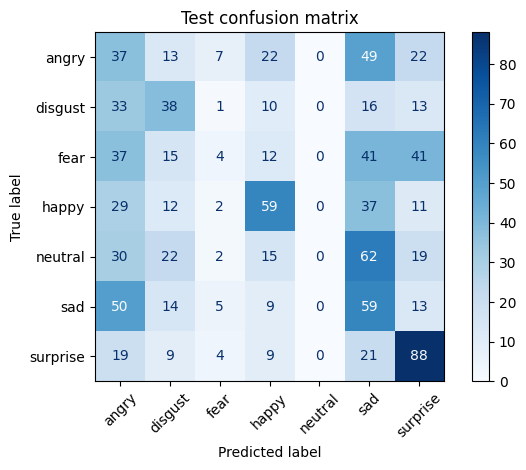

In [11]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import numpy as np

model.eval()
y_true, y_pred = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        predictions = model(images).argmax(1).cpu().numpy()

        y_pred.extend(predictions)
        y_true.extend(labels.numpy())

print(classification_report(
    y_true, y_pred, labels=list(range(len(class_names))),
    target_names=class_names, zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred,
    labels=list(range(len(class_names))),
    display_labels=class_names,
    xticks_rotation=45,
    cmap="Blues"
)
plt.title("Test confusion matrix")
plt.tight_layout()
plt.show()

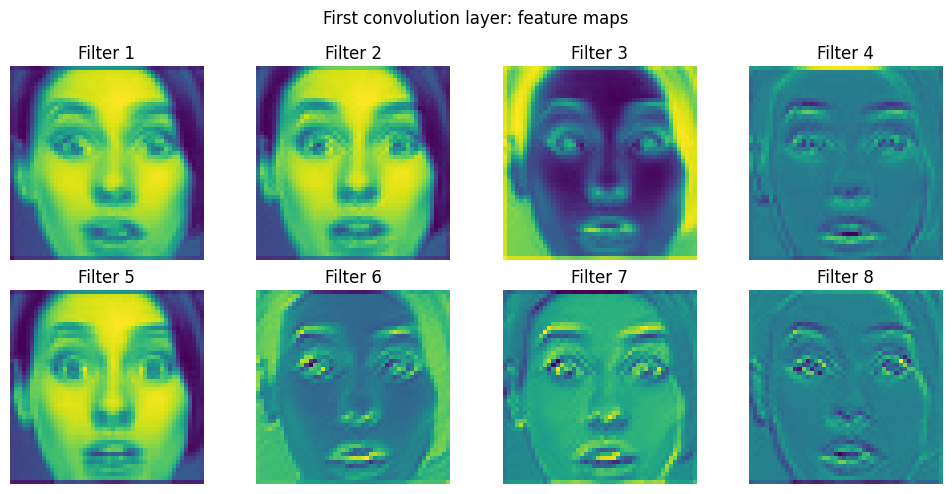

In [12]:
# Get the first convolution layer's activations.
model.eval()
images, labels = next(iter(test_loader))
sample = images[0:1].to(device)

with torch.no_grad():
    feature_maps = model.features[0](sample).squeeze(0).cpu()

fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[i], cmap="viridis")
    ax.set_title(f"Filter {i+1}")
    ax.axis("off")

plt.suptitle("First convolution layer: feature maps")
plt.tight_layout()
plt.show()

In [13]:
!pip -q install gradio opencv-python-headless

In [15]:
!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless
!pip install -q opencv-python-headless

Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93
Found existing installation: opencv-contrib-python 4.14.0.94
Uninstalling opencv-contrib-python-4.14.0.94:
  Successfully uninstalled opencv-contrib-python-4.14.0.94


In [17]:
import cv2

print("OpenCV version:", cv2.__version__)
print("OpenCV path:", cv2.__file__)
print("CascadeClassifier available:", hasattr(cv2, "CascadeClassifier"))

OpenCV version: 5.0.0
OpenCV path: /usr/local/lib/python3.13/dist-packages/cv2/__init__.py
CascadeClassifier available: False


In [18]:
import numpy as np
from PIL import Image, ImageOps

def prepare_face(image):
    # Convert uploaded image to grayscale
    gray = ImageOps.grayscale(image)

    # Center-crop to a square
    width, height = gray.size
    side = min(width, height)

    left = (width - side) // 2
    top = (height - side) // 2

    gray = gray.crop((
        left, top,
        left + side, top + side
    ))

    # Resize to the CNN input dimensions
    gray = gray.resize((48, 48))

    return np.array(gray), "Image converted to grayscale and resized."

In [21]:
import torch
import gradio as gr
from PIL import Image

def predict_expression(image):
    if image is None:
        return {}, None, "Please upload an image."

    face, message = prepare_face(image)

    tensor = torch.tensor(
        face, dtype=torch.float32
    ).unsqueeze(0).unsqueeze(0) / 255.0

    tensor = tensor.to(device)

    model.eval()
    with torch.no_grad():
        logits = model(tensor)
        probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()

    scores = {
        class_names[i]: float(probabilities[i])
        for i in range(len(class_names))
    }

    return scores, Image.fromarray(face), message

In [22]:
demo = gr.Interface(
    fn=predict_expression,
    inputs=gr.Image(type="pil", label="Upload a face image"),
    outputs=[
        gr.Label(num_top_classes=7, label="Expression predictions"),
        gr.Image(label="Processed 48 × 48 image"),
        gr.Textbox(label="Preprocessing status")
    ],
    title="CNN Facial Expression Classifier",
    description="An educational CNN trained on FER-2013."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://bef41f35fa8735d9e3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
